# Fine-Tuning TinyLlama for Sentiment Classification

This chapter fine-tunes TinyLlama 1.1B for three-class sentiment classification
(negative / neutral / positive) using `AutoModelForSequenceClassification` with QLoRA (4-bit quantization + LoRA adapters). This is the standard approach for classification fine-tuning of compact LLMs — the model outputs a label directly, no text generation needed.

Code execution is disabled in Quarto (`eval: false`) because training runs in Colab Pro (A100 GPU, ~30–45 min). Results are hardcoded after the run.

## Install dependencies

In [1]:
#| label: install-dependencies
#| echo: true
#| eval: false

!pip install -q transformers peft bitsandbytes accelerate datasets pyarrow

## Imports

In [2]:
#| label: imports
#| echo: true
#| eval: false

import pandas as pd
import numpy as np
import torch

from pathlib import Path
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from sklearn.metrics import f1_score, classification_report

## Configuration

In [3]:
#| label: config
#| echo: true
#| eval: false

MODEL_NAME  = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
SEED        = 42
MAX_LENGTH  = 512
LABEL2ID    = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL    = {0: "negative", 1: "neutral", 2: "positive"}

## Mount Google Drive and load data

In [4]:
#| label: colab-drive-and-load-data
#| echo: true
#| eval: false

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/CLT/project")

train_df = pd.read_parquet(PROJECT_DIR / "train.parquet")
test_df  = pd.read_parquet(PROJECT_DIR / "test.parquet")

print(f"Train: {len(train_df):,}  |  Test: {len(test_df):,}")
print("Label distribution (train):")
print(train_df["sentiment_label"].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 13,053  |  Test: 3,264
Label distribution (train):
sentiment_label
neutral              7977
positive             3130
(partly) negative    1946
Name: count, dtype: int64


## Prepare datasets

We recode "(partly) negative" to "negative" and tokenize `full_content` (truncated to 512 tokens) and map the string labels to integers.

In [5]:
#| label: recode-sentiment
#| echo: true
#| eval: false

train_df["sentiment_label"] = train_df["sentiment_label"].str.replace("(partly) negative", "negative")
test_df["sentiment_label"]  = test_df["sentiment_label"].str.replace("(partly) negative", "negative")

print(train_df["sentiment_label"].unique())
print(test_df["sentiment_label"].unique())

['neutral' 'positive' 'negative']
['neutral' 'negative' 'positive']


In [6]:
#| label: prepare-datasets
#| echo: true
#| eval: false

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def tokenize(batch):
    enc = tokenizer(
        batch["full_content"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length",
    )
    enc["labels"] = [LABEL2ID[l] for l in batch["sentiment_label"]]
    return enc

train_dataset = Dataset.from_pandas(train_df[["full_content", "sentiment_label"]]) \
    .map(tokenize, batched=True, remove_columns=["full_content", "sentiment_label"])

test_dataset  = Dataset.from_pandas(test_df[["full_content", "sentiment_label"]]) \
    .map(tokenize, batched=True, remove_columns=["full_content", "sentiment_label"])

train_dataset.set_format("torch")
test_dataset.set_format("torch")

print(f"Train samples: {len(train_dataset):,}")
print(f"Test  samples: {len(test_dataset):,}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Map:   0%|          | 0/13053 [00:00<?, ? examples/s]

Map:   0%|          | 0/3264 [00:00<?, ? examples/s]

Train samples: 13,053
Test  samples: 3,264


## Configure 4-bit quantization

In [7]:
#| label: quantization-config
#| echo: true
#| eval: false

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

## Load model

We load TinyLlama with a classification head (`num_labels=3`) instead of the causal LM head.
This replaces the generative output with a direct 3-class softmax — cleaner and more stable
for classification.

In [8]:
#| label: load-model
#| echo: true
#| eval: false

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    quantization_config=bnb_config,
    device_map="auto",
)

model.config.pad_token_id = tokenizer.pad_token_id
model = prepare_model_for_kbit_training(model)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

LlamaForSequenceClassification LOAD REPORT from: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Configure LoRA

In [9]:
#| label: lora-config
#| echo: true
#| eval: false

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",       # Sequence Classification — nicht CAUSAL_LM
    target_modules=["q_proj", "v_proj"],
)

model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

trainable params: 2,258,944 || all params: 1,036,777,472 || trainable%: 0.2179


## Training arguments

In [10]:
#| label: training-args
#| echo: true
#| eval: false

training_args = TrainingArguments(
    output_dir="outputs/tinyllama-sentiment",
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    num_train_epochs=3,
    learning_rate=2e-4,
    logging_steps=50,
    save_strategy="no",
    report_to="none",
    fp16=True,
    seed=SEED,
)

## Metrics function

In [11]:
#| label: metrics-fn
#| echo: true
#| eval: false

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    macro_f1 = f1_score(labels, preds, average="macro")
    return {"macro_f1": macro_f1}

## Trainer

In [12]:
#| label: trainer
#| echo: true
#| eval: false

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

In [13]:
#| label: train
#| echo: true
#| eval: false

trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1181: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
50,2.470318
100,1.783229
150,1.460075
200,1.214954
250,1.218497
300,1.149991
350,1.116714
400,1.178946
450,1.052051
500,1.068193


TrainOutput(global_step=2448, training_loss=0.9523108176935732, metrics={'train_runtime': 1708.8097, 'train_samples_per_second': 22.916, 'train_steps_per_second': 1.433, 'total_flos': 1.1683689923189146e+17, 'train_loss': 0.9523108176935732, 'epoch': 3.0})

## Training loss curve

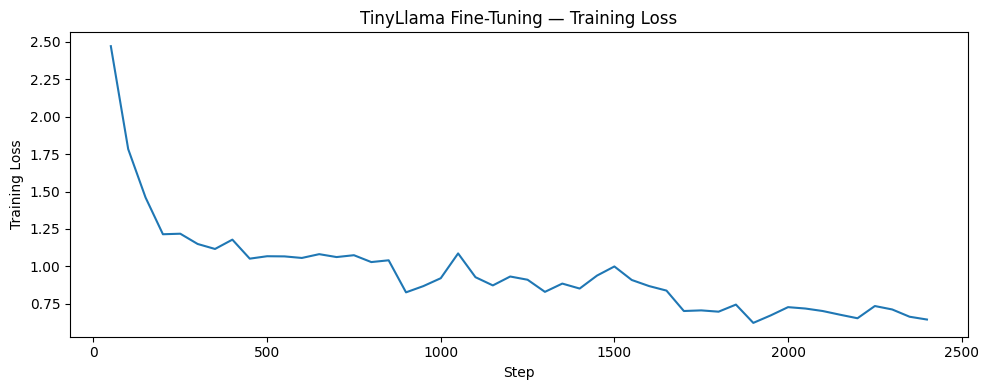

In [14]:
#| label: training-loss-curve
#| echo: true
#| eval: false

import matplotlib.pyplot as plt

loss_log = trainer.state.log_history
steps  = [x["step"] for x in loss_log if "loss" in x]
losses = [x["loss"] for x in loss_log if "loss" in x]

plt.figure(figsize=(10, 4))
plt.plot(steps, losses)
plt.xlabel("Step")
plt.ylabel("Training Loss")
plt.title("TinyLlama Fine-Tuning — Training Loss")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "training_loss.png")
plt.show()

## Evaluate

In [15]:
#| label: evaluate
#| echo: true
#| eval: false

predictions = trainer.predict(test_dataset)
y_pred = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

y_pred_labels = [ID2LABEL[i] for i in y_pred]
y_true_labels = [ID2LABEL[i] for i in y_true]

macro_f1 = f1_score(y_true_labels, y_pred_labels, average="macro",
                    labels=["negative", "neutral", "positive"])

print(f"Macro-F1: {macro_f1:.4f}")
print()
print(classification_report(y_true_labels, y_pred_labels,
                             labels=["negative", "neutral", "positive"]))

Macro-F1: 0.7569

              precision    recall  f1-score   support

    negative       0.76      0.68      0.72       487
     neutral       0.81      0.85      0.83      1995
    positive       0.74      0.69      0.72       782

    accuracy                           0.79      3264
   macro avg       0.77      0.74      0.76      3264
weighted avg       0.79      0.79      0.79      3264



## Save model and results

In [16]:
#| label: save-model
#| echo: true
#| eval: false

trainer.model.save_pretrained(PROJECT_DIR / "tinyllama-sentiment")
tokenizer.save_pretrained(PROJECT_DIR / "tinyllama-sentiment")
print("Model saved.")

Model saved.


In [17]:
#| label: save-results
#| echo: true
#| eval: false

results_df = pd.DataFrame({"true": y_true_labels, "pred": y_pred_labels})
results_df.to_csv(PROJECT_DIR / "tinyllama_predictions.csv", index=False)

with open(PROJECT_DIR / "tinyllama_results.txt", "w") as f:
    f.write(f"Macro-F1: {macro_f1}\n")
    f.write(classification_report(y_true_labels, y_pred_labels,
                                   labels=["negative", "neutral", "positive"]))

print("Results saved.")

Results saved.
